# Multi-Image Panorama Stitching

Computer Vision Project using the PASSTA LunchRoom Dataset.

**Pipeline:** Harris → SIFT → Matching → RANSAC → Homography → Warping → Blending.

Dataset: 12 consecutive images selected from 72 images.

## 1. Project Setup

In [1]:
from pathlib import Path
import re
import math
import warnings
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("SIFT available:", hasattr(cv2, "SIFT_create"))

if not hasattr(cv2, "SIFT_create"):
    raise RuntimeError(
        "SIFT is not available in this OpenCV installation. "
        "Check the installed opencv-python package."
    )

# Resolve the repository root whether the notebook is opened from
# the repository root or from the notebooks/ folder.
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_DIR = PROJECT_ROOT / "dataset" / "LunchRoom"
IMAGE_DIR = DATASET_DIR / "images"
CALIBRATION_PATH = DATASET_DIR / "Calibration.txt"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Dataset selection
IMAGE_START_NUMBER = 1
NUMBER_OF_IMAGES = 12

# Preprocessing
MAX_IMAGE_DIMENSION = 1000
APPLY_UNDISTORTION = False

# Lab 6 feature pipeline parameters
MAX_CORNERS = 800
HARRIS_QUALITY_LEVEL = 0.01
HARRIS_MIN_DISTANCE = 5
HARRIS_K = 0.04
SIFT_KEYPOINT_SIZE = 16

# Matching and RANSAC
LOWE_RATIO = 0.75
RANSAC_REPROJECTION_THRESHOLD = 5.0

# Safety limit to avoid allocating an unexpectedly huge panorama
MAX_CANVAS_PIXELS = 40_000_000

print("Project root:", PROJECT_ROOT)
print("Image directory:", IMAGE_DIR)
print("Output directory:", OUTPUT_DIR)

OpenCV: 5.1.0
NumPy: 2.5.5
SIFT available: True
Project root: D:\Task3_CV\panorama-stitching-computer-vision
Image directory: D:\Task3_CV\panorama-stitching-computer-vision\dataset\LunchRoom\images
Output directory: D:\Task3_CV\panorama-stitching-computer-vision\outputs


## 2. Inspect the Dataset and Select a Consecutive Image Sequence

The dataset contains images named `img01.jpg` through `img72.jpg`.

We select **consecutive** images because adjacent frames are expected to have sufficient overlap. Do not randomly select images from the sequence: images with insufficient overlap may not match reliably.

In [2]:
if not IMAGE_DIR.exists():
    raise FileNotFoundError(
        f"Image folder was not found: {IMAGE_DIR}\n"
        "Expected location: dataset/LunchRoom/images/"
    )

image_paths_all = sorted(
    IMAGE_DIR.glob("img*.jpg"),
    key=lambda p: int(re.search(r"img(\d+)", p.stem).group(1))
)

print("Total JPG images found:", len(image_paths_all))

if len(image_paths_all) == 0:
    raise RuntimeError("No img*.jpg files were found in the dataset folder.")

selected_start = IMAGE_START_NUMBER - 1
selected_end = selected_start + NUMBER_OF_IMAGES

if selected_end > len(image_paths_all):
    raise ValueError(
        f"Requested {NUMBER_OF_IMAGES} images starting at "
        f"img{IMAGE_START_NUMBER:02d}, but only {len(image_paths_all)} images exist."
    )

selected_paths = image_paths_all[selected_start:selected_end]

print("\nSelected image sequence:")
for path in selected_paths:
    print(" -", path.name)

assert len(selected_paths) == NUMBER_OF_IMAGES

Total JPG images found: 72

Selected image sequence:
 - img01.jpg
 - img02.jpg
 - img03.jpg
 - img04.jpg
 - img05.jpg
 - img06.jpg
 - img07.jpg
 - img08.jpg
 - img09.jpg
 - img10.jpg
 - img11.jpg
 - img12.jpg


## 3. Camera Calibration

Camera intrinsic and distortion parameters were loaded
from Calibration.txt.

Undistortion was skipped because the loaded image
dimensions do not match the calibration resolution.

In [3]:
if not CALIBRATION_PATH.exists():
    raise FileNotFoundError(
        f"Calibration file not found: {CALIBRATION_PATH}"
    )

calibration_text = CALIBRATION_PATH.read_text(encoding="utf-8", errors="ignore")

def read_calibration_value(label, text):
    pattern = rf"\b{re.escape(label)}\s*:\s*([-+]?(?:\d+\.?\d*|\.\d+)(?:[eE][-+]?\d+)?)"
    match = re.search(pattern, text, flags=re.IGNORECASE)
    if match is None:
        raise ValueError(f"Could not find calibration parameter: {label}")
    return float(match.group(1))

resolution_match = re.search(
    r"Image Resolution:\s*(\d+)\s*x\s*(\d+)",
    calibration_text,
    flags=re.IGNORECASE
)
if resolution_match is None:
    raise ValueError("Could not read Image Resolution from Calibration.txt")

calibration_width = int(resolution_match.group(1))
calibration_height = int(resolution_match.group(2))

fx = read_calibration_value("Fx", calibration_text)
fy = read_calibration_value("Fy", calibration_text)
cx = read_calibration_value("Cx", calibration_text)
cy = read_calibration_value("Cy", calibration_text)

k1 = read_calibration_value("K1", calibration_text)
k2 = read_calibration_value("K2", calibration_text)
k3 = read_calibration_value("K3", calibration_text)
p1 = read_calibration_value("P1", calibration_text)
p2 = read_calibration_value("P2", calibration_text)

camera_matrix_original = np.array([
    [fx, 0.0, cx],
    [0.0, fy, cy],
    [0.0, 0.0, 1.0]
], dtype=np.float64)

distortion_coefficients = np.array(
    [k1, k2, p1, p2, k3],
    dtype=np.float64
)

print("Calibration resolution:", calibration_width, "x", calibration_height)
print("\nCamera matrix K:")
print(camera_matrix_original)
print("\nDistortion coefficients [K1, K2, P1, P2, K3]:")
print(distortion_coefficients)

Calibration resolution: 5472 x 3648

Camera matrix K:
[[2.56931e+03 0.00000e+00 2.75564e+03]
 [0.00000e+00 2.56696e+03 1.78842e+03]
 [0.00000e+00 0.00000e+00 1.00000e+00]]

Distortion coefficients [K1, K2, P1, P2, K3]:
[-0.0484573   0.0100024   0.00050623  0.00060361  0.        ]


## 4. Image Preprocessing

Images were resized to a maximum dimension of 1000 pixels.

In [4]:
def resize_longest_side(image, max_dimension=1000):
    height, width = image.shape[:2]
    longest_side = max(height, width)

    if longest_side <= max_dimension:
        return image.copy()

    scale = max_dimension / float(longest_side)
    new_width = int(round(width * scale))
    new_height = int(round(height * scale))

    return cv2.resize(
        image,
        (new_width, new_height),
        interpolation=cv2.INTER_AREA
    )


def preprocess_image(image_path):
    # Standard color read. OpenCV returns BGR channel order.
    image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)

    if image is None:
        raise ValueError(f"OpenCV could not read image: {image_path}")

    original_height, original_width = image.shape[:2]
    resized = resize_longest_side(image, MAX_IMAGE_DIMENSION)

    undistortion_applied = False

    if APPLY_UNDISTORTION:
        dimensions_match = (
            original_width == calibration_width
            and original_height == calibration_height
        )

        if dimensions_match:
            resized_height, resized_width = resized.shape[:2]
            scale_x = resized_width / float(calibration_width)
            scale_y = resized_height / float(calibration_height)

            camera_matrix_resized = camera_matrix_original.copy()
            camera_matrix_resized[0, 0] *= scale_x  # fx
            camera_matrix_resized[0, 2] *= scale_x  # cx
            camera_matrix_resized[1, 1] *= scale_y  # fy
            camera_matrix_resized[1, 2] *= scale_y  # cy

            resized = cv2.undistort(
                resized,
                camera_matrix_resized,
                distortion_coefficients
            )
            undistortion_applied = True
        else:
            warnings.warn(
                f"Undistortion skipped for {image_path.name}: "
                f"loaded size is {original_width}x{original_height}, while "
                f"Calibration.txt specifies {calibration_width}x{calibration_height}. "
                "Check image orientation and calibration dimensions."
            )

    metadata = {
        "filename": image_path.name,
        "original_width": original_width,
        "original_height": original_height,
        "processed_width": resized.shape[1],
        "processed_height": resized.shape[0],
        "undistortion_applied": undistortion_applied
    }

    return resized, metadata


images = []
image_metadata = []

for image_path in selected_paths:
    processed_image, metadata = preprocess_image(image_path)
    images.append(processed_image)
    image_metadata.append(metadata)

print(f"Successfully loaded {len(images)} images.")

for item in image_metadata:
    print(
        f"{item['filename']}: "
        f"{item['original_width']}x{item['original_height']} -> "
        f"{item['processed_width']}x{item['processed_height']} | "
        f"Undistortion: {item['undistortion_applied']}"
    )

Successfully loaded 12 images.
img01.jpg: 3648x5472 -> 667x1000 | Undistortion: False
img02.jpg: 3648x5472 -> 667x1000 | Undistortion: False
img03.jpg: 3648x5472 -> 667x1000 | Undistortion: False
img04.jpg: 3648x5472 -> 667x1000 | Undistortion: False
img05.jpg: 3648x5472 -> 667x1000 | Undistortion: False
img06.jpg: 3648x5472 -> 667x1000 | Undistortion: False
img07.jpg: 3648x5472 -> 667x1000 | Undistortion: False
img08.jpg: 3648x5472 -> 667x1000 | Undistortion: False
img09.jpg: 3648x5472 -> 667x1000 | Undistortion: False
img10.jpg: 3648x5472 -> 667x1000 | Undistortion: False
img11.jpg: 3648x5472 -> 667x1000 | Undistortion: False
img12.jpg: 3648x5472 -> 667x1000 | Undistortion: False


## 5. Visualize the Selected Images

A contact sheet helps us verify the order and visual continuity of the selected frames before feature extraction.

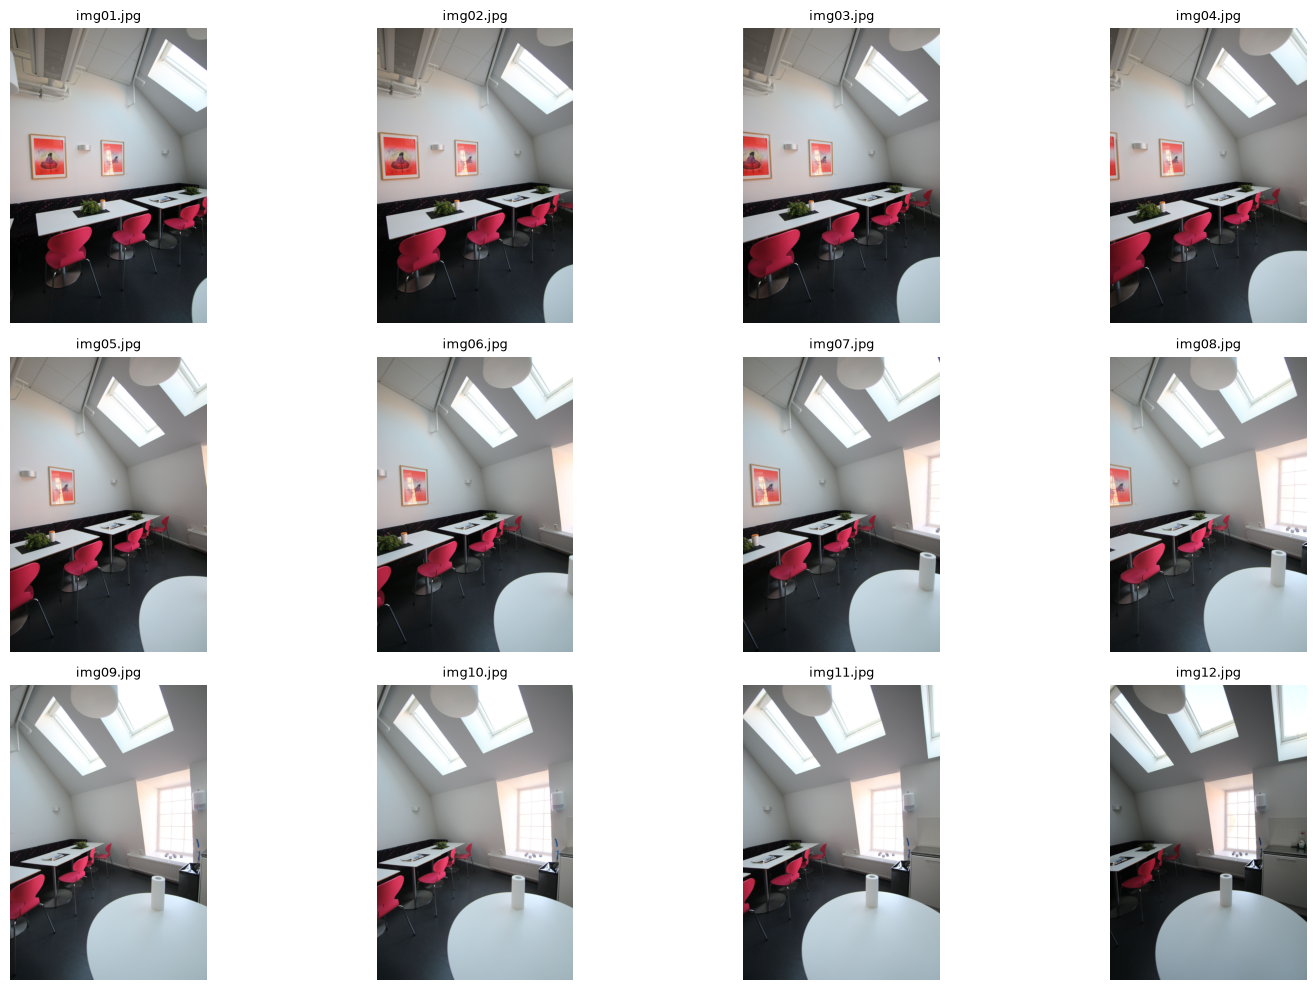

In [5]:
def show_bgr_images(image_list, titles=None, cols=4, figsize=(16, 9)):
    count = len(image_list)
    rows = math.ceil(count / cols)

    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = np.array(axes).reshape(-1)

    for index, ax in enumerate(axes):
        ax.axis("off")

        if index < count:
            rgb = cv2.cvtColor(image_list[index], cv2.COLOR_BGR2RGB)
            ax.imshow(rgb)
            if titles is not None:
                ax.set_title(titles[index], fontsize=9)

    plt.tight_layout()
    plt.show()


show_bgr_images(
    images,
    titles=[path.name for path in selected_paths],
    cols=4,
    figsize=(16, 10)
)

## 6. Harris Corner Detection

Harris provides candidate corner locations. In this lab's hybrid approach, these locations are then passed to SIFT to compute descriptors.

The parameters follow Lab 6:
- `maxCorners = 800`
- `qualityLevel = 0.01`
- `minDistance = 5`
- `useHarrisDetector = True`
- `k = 0.04`

In [6]:
def detect_harris_corners(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    corners = cv2.goodFeaturesToTrack(
        gray,
        maxCorners=MAX_CORNERS,
        qualityLevel=HARRIS_QUALITY_LEVEL,
        minDistance=HARRIS_MIN_DISTANCE,
        useHarrisDetector=True,
        k=HARRIS_K
    )

    if corners is None:
        return []

    keypoints = [
        cv2.KeyPoint(float(x), float(y), SIFT_KEYPOINT_SIZE)
        for x, y in corners.reshape(-1, 2)
    ]

    return keypoints


harris_keypoints = [detect_harris_corners(image) for image in images]

for path, keypoints in zip(selected_paths, harris_keypoints):
    print(f"{path.name}: {len(keypoints)} Harris corners")

img01.jpg: 123 Harris corners
img02.jpg: 118 Harris corners
img03.jpg: 112 Harris corners
img04.jpg: 117 Harris corners
img05.jpg: 107 Harris corners
img06.jpg: 109 Harris corners
img07.jpg: 101 Harris corners
img08.jpg: 122 Harris corners
img09.jpg: 98 Harris corners
img10.jpg: 92 Harris corners
img11.jpg: 93 Harris corners
img12.jpg: 87 Harris corners


### Visualize Harris Corners

The red/colored markers show the detected Harris corner locations on a sample image.

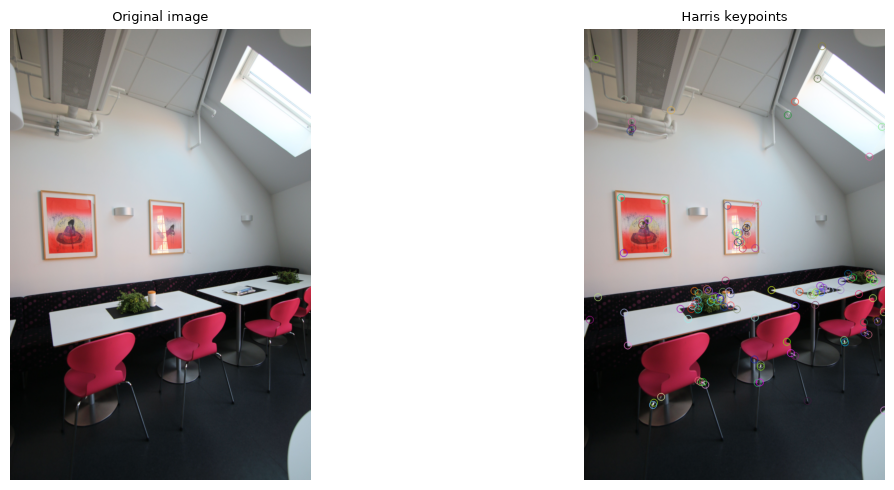

In [7]:
sample_index = 0

harris_visualization = cv2.drawKeypoints(
    images[sample_index],
    harris_keypoints[sample_index],
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

show_bgr_images(
    [images[sample_index], harris_visualization],
    titles=["Original image", "Harris keypoints"],
    cols=2,
    figsize=(14, 5)
)

## 7. Compute SIFT Descriptors at Harris Locations

Harris answers **where** the candidate corners are. SIFT describes the local appearance around each point.

Each SIFT descriptor has 128 values. We use `sift.compute()` on the Harris keypoints, as demonstrated in Lab 6. This is the lab's Harris + SIFT hybrid, not the standard SIFT keypoint detection pipeline.

In [8]:
sift = cv2.SIFT_create()

feature_keypoints = []
descriptors = []

for image, keypoints in zip(images, harris_keypoints):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    computed_keypoints, descriptor_array = sift.compute(gray, keypoints)

    if computed_keypoints is None or descriptor_array is None:
        computed_keypoints = []
        descriptor_array = None

    feature_keypoints.append(computed_keypoints)
    descriptors.append(descriptor_array)

for index, (keypoints, descriptor_array) in enumerate(
    zip(feature_keypoints, descriptors)
):
    descriptor_shape = None if descriptor_array is None else descriptor_array.shape
    print(
        f"{selected_paths[index].name}: "
        f"{len(keypoints)} keypoints, descriptor shape = {descriptor_shape}"
    )

if any(desc is None or len(desc) < 4 for desc in descriptors):
    raise RuntimeError(
        "At least one image has too few SIFT descriptors. "
        "Try increasing image detail or adjusting the Harris parameters."
    )

img01.jpg: 123 keypoints, descriptor shape = (123, 128)
img02.jpg: 118 keypoints, descriptor shape = (118, 128)
img03.jpg: 112 keypoints, descriptor shape = (112, 128)
img04.jpg: 117 keypoints, descriptor shape = (117, 128)
img05.jpg: 107 keypoints, descriptor shape = (107, 128)
img06.jpg: 109 keypoints, descriptor shape = (109, 128)
img07.jpg: 101 keypoints, descriptor shape = (101, 128)
img08.jpg: 122 keypoints, descriptor shape = (122, 128)
img09.jpg: 98 keypoints, descriptor shape = (98, 128)
img10.jpg: 92 keypoints, descriptor shape = (92, 128)
img11.jpg: 93 keypoints, descriptor shape = (93, 128)
img12.jpg: 87 keypoints, descriptor shape = (87, 128)


## 8. Feature Matching with BFMatcher and Lowe's Ratio Test

For SIFT descriptors, we use Euclidean distance (`cv2.NORM_L2`).

`knnMatch(..., k=2)` returns the best and second-best candidate for each query descriptor. Lowe's ratio test keeps a match only when:

`best.distance < 0.75 * second_best.distance`

For every adjacent pair, the source image is the later image and the reference image is the previous image. Therefore, the homography estimated later maps **source → reference**.

In [9]:
matcher = cv2.BFMatcher(cv2.NORM_L2)


def match_descriptors(reference_index, source_index, ratio=LOWE_RATIO):
    reference_descriptors = descriptors[reference_index]
    source_descriptors = descriptors[source_index]

    knn_matches = matcher.knnMatch(
        source_descriptors,
        reference_descriptors,
        k=2
    )

    good_matches = []
    for pair in knn_matches:
        if len(pair) < 2:
            continue

        best_match, second_best_match = pair

        if best_match.distance < ratio * second_best_match.distance:
            good_matches.append(best_match)

    return knn_matches, good_matches


# Inspect the first adjacent pair.
first_knn_matches, first_good_matches = match_descriptors(0, 1)

print("Candidate KNN pairs:", len(first_knn_matches))
print("Matches after Lowe's ratio test:", len(first_good_matches))

Candidate KNN pairs: 118
Matches after Lowe's ratio test: 105


### Visualize Good Matches

The left side is the source image (`img02`) and the right side is the reference image (`img01`). Match lines connect corresponding feature descriptors.

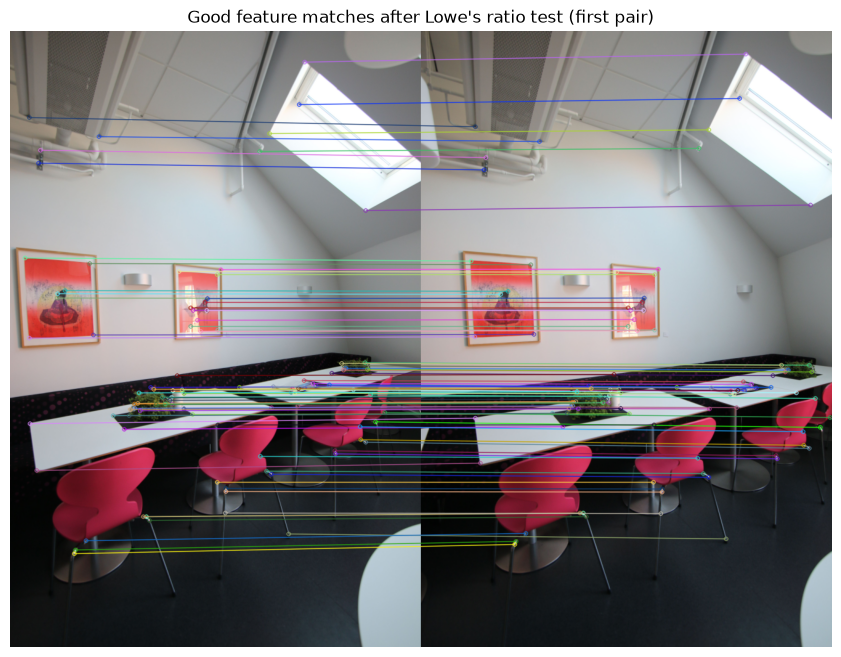

In [10]:
if len(first_good_matches) > 0:
    matches_visualization = cv2.drawMatches(
        images[1],
        feature_keypoints[1],
        images[0],
        feature_keypoints[0],
        first_good_matches[:100],
        None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    plt.figure(figsize=(18, 8))
    plt.imshow(cv2.cvtColor(matches_visualization, cv2.COLOR_BGR2RGB))
    plt.title("Good feature matches after Lowe's ratio test (first pair)")
    plt.axis("off")
    plt.show()
else:
    print("No good matches found for the first pair.")

## 9. Estimate Pairwise Homographies with RANSAC

For each adjacent pair:
- Source points come from image `i + 1`.
- Destination points come from image `i`.
- `cv2.findHomography()` estimates a 3×3 projective transformation.
- RANSAC rejects incorrect matches using a reprojection-error threshold of 5 pixels.

The resulting matrix `H_source_to_reference` maps image `i + 1` into image `i`.

In [11]:
def estimate_pairwise_homography(reference_index, source_index):
    _, good_matches = match_descriptors(reference_index, source_index)

    if len(good_matches) < 4:
        raise RuntimeError(
            f"Not enough good matches between "
            f"{selected_paths[source_index].name} and "
            f"{selected_paths[reference_index].name}: {len(good_matches)}"
        )

    source_points = np.float32([
        feature_keypoints[source_index][match.queryIdx].pt
        for match in good_matches
    ]).reshape(-1, 1, 2)

    destination_points = np.float32([
        feature_keypoints[reference_index][match.trainIdx].pt
        for match in good_matches
    ]).reshape(-1, 1, 2)

    homography, inlier_mask = cv2.findHomography(
        source_points,
        destination_points,
        cv2.RANSAC,
        RANSAC_REPROJECTION_THRESHOLD
    )

    if homography is None or inlier_mask is None:
        raise RuntimeError(
            f"Homography estimation failed for pair "
            f"{selected_paths[reference_index].name} <- "
            f"{selected_paths[source_index].name}"
        )

    inlier_mask = inlier_mask.ravel().astype(bool)
    inlier_count = int(np.sum(inlier_mask))

    return homography, good_matches, inlier_mask


pairwise_homographies = []
pairwise_statistics = []

for index in range(len(images) - 1):
    H_source_to_reference, good_matches, inlier_mask = (
        estimate_pairwise_homography(index, index + 1)
    )

    pairwise_homographies.append(H_source_to_reference)

    total_matches = len(good_matches)
    inliers = int(np.sum(inlier_mask))
    outliers = total_matches - inliers
    inlier_ratio = inliers / total_matches if total_matches else 0.0

    pairwise_statistics.append({
        "reference": selected_paths[index].name,
        "source": selected_paths[index + 1].name,
        "good_matches": total_matches,
        "inliers": inliers,
        "outliers": outliers,
        "inlier_ratio": inlier_ratio
    })

    print(
        f"{selected_paths[index + 1].name} -> {selected_paths[index].name}: "
        f"{total_matches} good matches, "
        f"{inliers} inliers, {outliers} outliers, "
        f"inlier ratio = {inlier_ratio:.3f}"
    )

img02.jpg -> img01.jpg: 105 good matches, 105 inliers, 0 outliers, inlier ratio = 1.000
img03.jpg -> img02.jpg: 100 good matches, 100 inliers, 0 outliers, inlier ratio = 1.000
img04.jpg -> img03.jpg: 108 good matches, 105 inliers, 3 outliers, inlier ratio = 0.972
img05.jpg -> img04.jpg: 104 good matches, 102 inliers, 2 outliers, inlier ratio = 0.981
img06.jpg -> img05.jpg: 93 good matches, 90 inliers, 3 outliers, inlier ratio = 0.968
img07.jpg -> img06.jpg: 88 good matches, 88 inliers, 0 outliers, inlier ratio = 1.000
img08.jpg -> img07.jpg: 75 good matches, 68 inliers, 7 outliers, inlier ratio = 0.907
img09.jpg -> img08.jpg: 56 good matches, 56 inliers, 0 outliers, inlier ratio = 1.000
img10.jpg -> img09.jpg: 90 good matches, 90 inliers, 0 outliers, inlier ratio = 1.000
img11.jpg -> img10.jpg: 83 good matches, 82 inliers, 1 outliers, inlier ratio = 0.988
img12.jpg -> img11.jpg: 65 good matches, 63 inliers, 2 outliers, inlier ratio = 0.969


### Visualize RANSAC Inliers and Outliers for the First Pair

Green lines are inliers accepted by RANSAC. Red lines are good descriptor matches rejected by the geometric model.

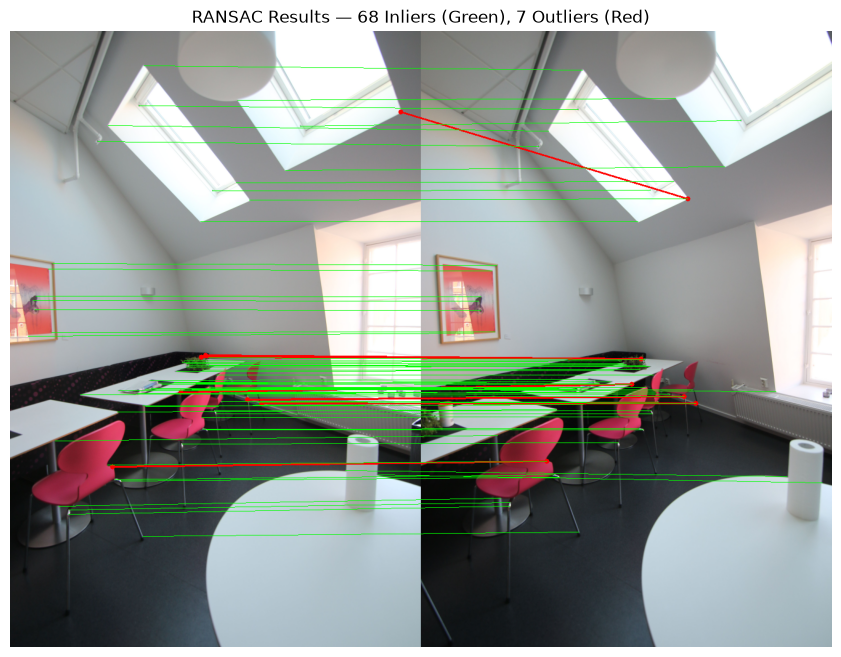

Source: img08.jpg -> Reference: img07.jpg
Total good matches: 75
Inliers: 68
Outliers: 7
Homography:
[[ 8.86463686e-01 -4.47064678e-03  6.12434367e+01]
 [-7.67157476e-02  9.47321520e-01  2.41979515e+01]
 [-1.68778995e-04  1.02873206e-06  1.00000000e+00]]


In [12]:

# Select an adjacent image pair that contains outliers
reference_index = 6
source_index = 7

H_first, good_first, inlier_mask_first = (
    estimate_pairwise_homography(reference_index, source_index)
)

# Separate inliers and outliers
inlier_matches = [
    match for match, is_inlier in zip(good_first, inlier_mask_first)
    if is_inlier
]

outlier_matches = [
    match for match, is_inlier in zip(good_first, inlier_mask_first)
    if not is_inlier
]


# Create a side-by-side canvas
source_image = images[source_index].copy()
reference_image = images[reference_index].copy()

h, w = source_image.shape[:2]

canvas = np.hstack((source_image, reference_image))

# Draw outliers in red
for match in outlier_matches:
    pt1 = tuple(
        np.round(feature_keypoints[source_index][match.queryIdx].pt).astype(int)
    )
    pt2 = tuple(
        np.round(feature_keypoints[reference_index][match.trainIdx].pt).astype(int)
    )

    pt2 = (pt2[0] + w, pt2[1])

    cv2.line(canvas, pt1, pt2, (0, 0, 255), 2)
    cv2.circle(canvas, pt1, 4, (0, 0, 255), -1)
    cv2.circle(canvas, pt2, 4, (0, 0, 255), -1)

# Draw inliers in green
for match in inlier_matches:
    pt1 = tuple(
        np.round(feature_keypoints[source_index][match.queryIdx].pt).astype(int)
    )
    pt2 = tuple(
        np.round(feature_keypoints[reference_index][match.trainIdx].pt).astype(int)
    )

    pt2 = (pt2[0] + w, pt2[1])

    cv2.line(canvas, pt1, pt2, (0, 255, 0), 1)

plt.figure(figsize=(18, 8))
plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
plt.title(
    f"RANSAC Results — {len(inlier_matches)} Inliers (Green), "
    f"{len(outlier_matches)} Outliers (Red)"
)
plt.axis("off")
plt.show()


print(
    f"Source: {selected_paths[source_index].name} "
    f"-> Reference: {selected_paths[reference_index].name}"
)
print(f"Total good matches: {len(good_first)}")
print(f"Inliers: {len(inlier_matches)}")
print(f"Outliers: {len(outlier_matches)}")
print("Homography:")
print(H_first)


## 10. Map Every Image into One Reference Coordinate System

Stitching more than two images requires all images to be transformed into one common coordinate frame.

We choose the middle image as the reference to reduce the amount of accumulated transformation in either direction.

Let `H[i+1 -> i]` be the pairwise homography from image `i+1` to image `i`.

- To the right of the reference, we compose the pairwise homographies directly.
- To the left of the reference, we invert the pairwise homographies before composing them.

The resulting `global_transforms[i]` maps image `i` into the reference image's coordinate system.

In [13]:
number_of_images = len(images)
reference_index = number_of_images // 2

global_transforms = [None] * number_of_images
global_transforms[reference_index] = np.eye(3, dtype=np.float64)

# Images to the right of the reference:
# H[i+1 -> i] maps the next image into the previous image.
for index in range(reference_index + 1, number_of_images):
    global_transforms[index] = (
        global_transforms[index - 1] @ pairwise_homographies[index - 1]
    )

# Images to the left of the reference:
# Invert H[i+1 -> i] to obtain H[i -> i+1].
for index in range(reference_index - 1, -1, -1):
    H_next_to_current = pairwise_homographies[index]
    H_current_to_next = np.linalg.inv(H_next_to_current)

    global_transforms[index] = (
        global_transforms[index + 1] @ H_current_to_next
    )

# Normalize matrices for easier inspection.
for index, transform in enumerate(global_transforms):
    if abs(transform[2, 2]) > 1e-12:
        global_transforms[index] = transform / transform[2, 2]

print("Reference image:", selected_paths[reference_index].name)

for index, transform in enumerate(global_transforms):
    print(f"\nTransform for {selected_paths[index].name} -> reference:")
    print(transform)

Reference image: img07.jpg

Transform for img01.jpg -> reference:
[[ 2.21872431e+00  5.84350087e-02 -6.68870357e+02]
 [ 8.37923981e-01  1.82316038e+00 -3.82394443e+02]
 [ 1.79743122e-03 -7.15213203e-06  1.00000000e+00]]

Transform for img02.jpg -> reference:
[[ 1.87253209e+00  3.98952272e-02 -4.78829752e+02]
 [ 6.04264222e-01  1.55786022e+00 -2.60766218e+02]
 [ 1.29378109e-03 -1.06942918e-05  1.00000000e+00]]

Transform for img03.jpg -> reference:
[[ 1.61446042e+00  2.35952208e-02 -3.37870076e+02]
 [ 4.28851420e-01  1.36773910e+00 -1.73837131e+02]
 [ 9.17526568e-04 -1.63372668e-05  1.00000000e+00]]

Transform for img04.jpg -> reference:
[[ 1.38089779e+00  1.38032591e-02 -2.09901685e+02]
 [ 2.68780624e-01  1.21013627e+00 -1.00312070e+02]
 [ 5.74542511e-04 -1.41825802e-05  1.00000000e+00]]

Transform for img05.jpg -> reference:
[[ 1.26091991e+00  1.00179867e-02 -1.43172078e+02]
 [ 1.80753565e-01  1.14398629e+00 -6.76645421e+01]
 [ 3.87636389e-04 -3.93649654e-06  1.00000000e+00]]

Transfo

## 11. Calculate the Panorama Canvas

Before warping, transform the four corners of every image into the reference coordinate system.

The minimum and maximum transformed coordinates define a canvas large enough to contain all images. A translation matrix moves negative coordinates into positive canvas coordinates.

In [14]:
all_transformed_corners = []

for image, transform in zip(images, global_transforms):
    height, width = image.shape[:2]

    corners = np.float32([
        [0, 0],
        [width - 1, 0],
        [width - 1, height - 1],
        [0, height - 1]
    ]).reshape(-1, 1, 2)

    transformed_corners = cv2.perspectiveTransform(corners, transform)
    all_transformed_corners.append(transformed_corners.reshape(-1, 2))

all_transformed_corners = np.vstack(all_transformed_corners)

if not np.isfinite(all_transformed_corners).all():
    raise RuntimeError("Non-finite transformed corner coordinates. Check homographies.")

margin = 10
min_x = math.floor(np.min(all_transformed_corners[:, 0])) - margin
min_y = math.floor(np.min(all_transformed_corners[:, 1])) - margin
max_x = math.ceil(np.max(all_transformed_corners[:, 0])) + margin
max_y = math.ceil(np.max(all_transformed_corners[:, 1])) + margin

canvas_width = int(max_x - min_x)
canvas_height = int(max_y - min_y)

if canvas_width <= 0 or canvas_height <= 0:
    raise RuntimeError("Invalid panorama canvas dimensions.")

canvas_pixels = canvas_width * canvas_height

print("Panorama canvas width:", canvas_width)
print("Panorama canvas height:", canvas_height)
print("Total canvas pixels:", canvas_pixels)

if canvas_pixels > MAX_CANVAS_PIXELS:
    raise RuntimeError(
        f"Canvas is unexpectedly large ({canvas_width}x{canvas_height}). "
        "This usually indicates an incorrect pairwise homography. "
        "Inspect the matches and RANSAC inliers before continuing."
    )

translation_matrix = np.array([
    [1.0, 0.0, -min_x],
    [0.0, 1.0, -min_y],
    [0.0, 0.0, 1.0]
], dtype=np.float64)

print("\nCanvas translation matrix:")
print(translation_matrix)

Panorama canvas width: 1841
Panorama canvas height: 1853
Total canvas pixels: 3411373

Canvas translation matrix:
[[  1.   0. 679.]
 [  0.   1. 393.]
 [  0.   0.   1.]]


## 12. Warp All Images into the Common Canvas

For each image, the complete transformation is:

`T @ G[i]`

where:
- `G[i]` maps image `i` into the reference coordinate system.
- `T` shifts the reference coordinate system into the positive panorama canvas.

We also warp a binary mask for every image. The mask tells us which canvas pixels are covered by that image.

Warped img01.jpg: 1841x1853
Warped img02.jpg: 1841x1853
Warped img03.jpg: 1841x1853
Warped img04.jpg: 1841x1853
Warped img05.jpg: 1841x1853
Warped img06.jpg: 1841x1853
Warped img07.jpg: 1841x1853
Warped img08.jpg: 1841x1853
Warped img09.jpg: 1841x1853
Warped img10.jpg: 1841x1853
Warped img11.jpg: 1841x1853
Warped img12.jpg: 1841x1853


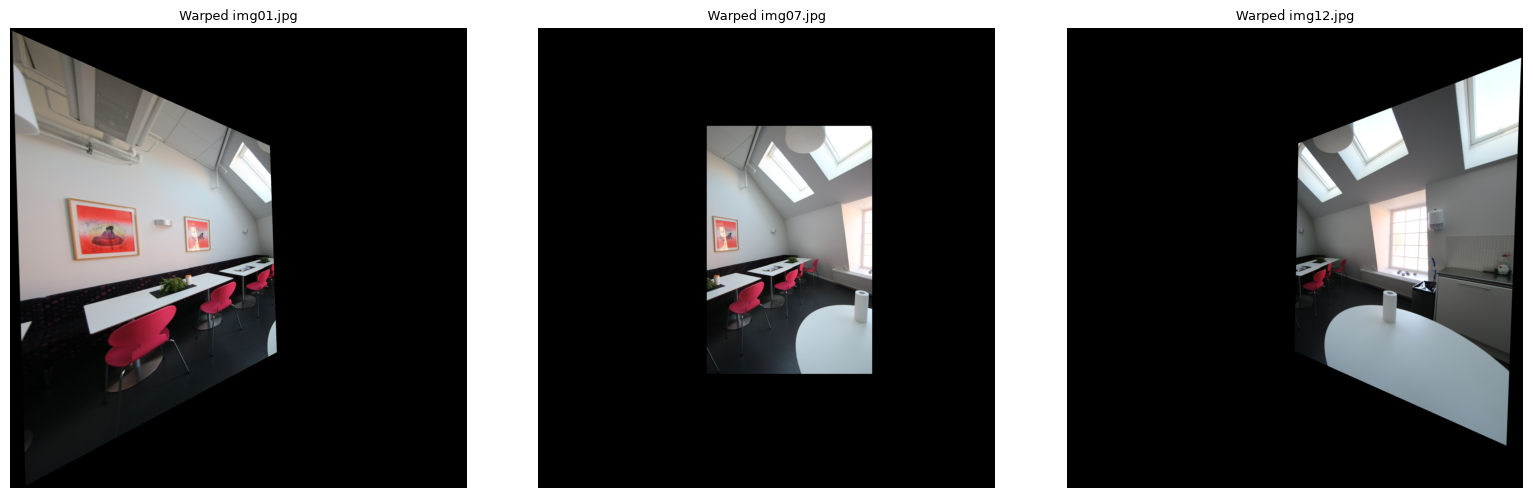

In [15]:
warped_images = []
warped_masks = []

for index, (image, global_transform) in enumerate(
    zip(images, global_transforms)
):
    final_transform = translation_matrix @ global_transform

    warped_image = cv2.warpPerspective(
        image,
        final_transform,
        (canvas_width, canvas_height)
    )

    source_mask = np.ones(image.shape[:2], dtype=np.uint8) * 255

    warped_mask = cv2.warpPerspective(
        source_mask,
        final_transform,
        (canvas_width, canvas_height),
        flags=cv2.INTER_NEAREST
    )

    warped_images.append(warped_image)
    warped_masks.append(warped_mask)

    print(
        f"Warped {selected_paths[index].name}: "
        f"{warped_image.shape[1]}x{warped_image.shape[0]}"
    )

# Display the warped reference image and the first/last warped images.
display_indices = sorted(set([0, reference_index, number_of_images - 1]))

show_bgr_images(
    [warped_images[i] for i in display_indices],
    titles=[f"Warped {selected_paths[i].name}" for i in display_indices],
    cols=3,
    figsize=(16, 5)
)

## 13. Blend the Warped Images — Simple Averaging

This is the blending method demonstrated in Lab 6.

For every panorama pixel:
- If one image covers the pixel, copy that image's value.
- If multiple images cover the pixel, average their values.
- If no image covers the pixel, the pixel remains black.

This produces a transparent baseline result. Exposure differences or moving objects may still create visible seams or ghosting.

Simple-average panorama saved to: D:\Task3_CV\panorama-stitching-computer-vision\outputs\panorama_simple_average.png


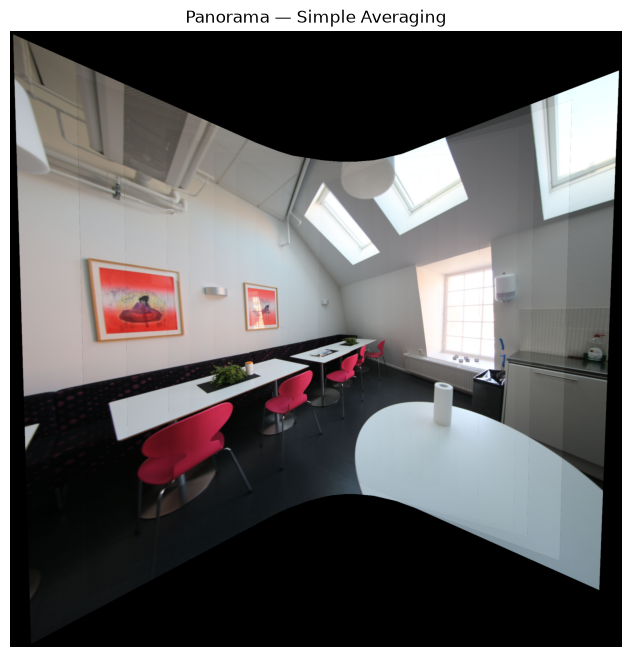

In [16]:
def blend_simple_average(warped_images, warped_masks):
    height, width = warped_images[0].shape[:2]

    image_sum = np.zeros((height, width, 3), dtype=np.float32)
    image_count = np.zeros((height, width), dtype=np.float32)

    for image, mask in zip(warped_images, warped_masks):
        valid_pixels = mask > 0

        image_sum[valid_pixels] += image[valid_pixels].astype(np.float32)
        image_count[valid_pixels] += 1.0

    safe_count = np.maximum(image_count, 1.0)

    panorama = image_sum / safe_count[:, :, None]
    panorama = np.clip(panorama, 0, 255).astype(np.uint8)

    coverage_mask = (image_count > 0).astype(np.uint8) * 255

    return panorama, coverage_mask, image_count


panorama_average, coverage_mask, overlap_count = blend_simple_average(
    warped_images,
    warped_masks
)

average_path = OUTPUT_DIR / "panorama_simple_average.png"
cv2.imwrite(str(average_path), panorama_average)

print("Simple-average panorama saved to:", average_path)

plt.figure(figsize=(18, 8))
plt.imshow(cv2.cvtColor(panorama_average, cv2.COLOR_BGR2RGB))
plt.title("Panorama — Simple Averaging")
plt.axis("off")
plt.show()

## 14. Optional Improved Blending — Feathering

Feather blending gives more weight to pixels farther from each image's boundary. This lets overlapping images fade into one another gradually and can reduce visible seams.

Simple averaging from the previous cell remains the baseline method from Lab 6. Feathering is an additional improvement.

Feathered panorama saved to: D:\Task3_CV\panorama-stitching-computer-vision\outputs\panorama_feathered.png


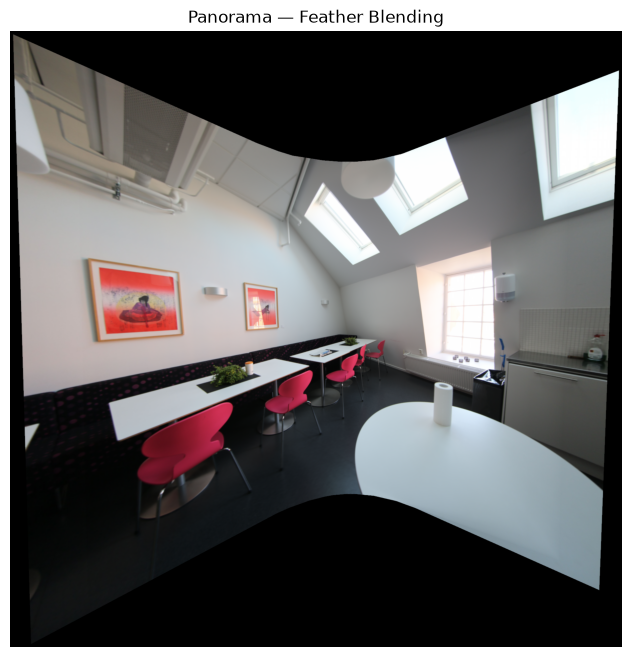

In [17]:
def blend_feathering(warped_images, warped_masks):
    height, width = warped_images[0].shape[:2]

    weighted_sum = np.zeros((height, width, 3), dtype=np.float32)
    weight_sum = np.zeros((height, width), dtype=np.float32)

    for image, mask in zip(warped_images, warped_masks):
        binary_mask = (mask > 0).astype(np.uint8)

        # Distance from each valid pixel to the nearest invalid/boundary pixel.
        distance = cv2.distanceTransform(
            binary_mask,
            cv2.DIST_L2,
            3
        )

        # Keep a positive weight for valid pixels, including boundary pixels.
        weights = np.maximum(distance, 1.0) * binary_mask
        weights = weights.astype(np.float32)

        weighted_sum += image.astype(np.float32) * weights[:, :, None]
        weight_sum += weights

    safe_weights = np.maximum(weight_sum, 1e-6)

    panorama = weighted_sum / safe_weights[:, :, None]
    panorama = np.clip(panorama, 0, 255).astype(np.uint8)

    coverage = (weight_sum > 0).astype(np.uint8) * 255

    return panorama, coverage, weight_sum


panorama_feather, feather_coverage, feather_weights = blend_feathering(
    warped_images,
    warped_masks
)

feather_path = OUTPUT_DIR / "panorama_feathered.png"
cv2.imwrite(str(feather_path), panorama_feather)

print("Feathered panorama saved to:", feather_path)

plt.figure(figsize=(18, 8))
plt.imshow(cv2.cvtColor(panorama_feather, cv2.COLOR_BGR2RGB))
plt.title("Panorama — Feather Blending")
plt.axis("off")
plt.show()

## 15. Crop Black Borders

Warping creates a non-rectangular valid image region. The coverage mask identifies valid panorama pixels independently of their color.

We calculate the largest axis-aligned rectangle fully covered by valid pixels. Cropping to this rectangle removes black border regions while retaining a clean rectangular output.

In [18]:
def largest_valid_rectangle(binary_mask):
    binary = (binary_mask > 0).astype(np.uint8)
    rows, cols = binary.shape

    heights = np.zeros(cols, dtype=np.int32)
    best_area = 0
    best_rectangle = None  # (x, y, width, height)

    for row in range(rows):
        heights = np.where(binary[row] > 0, heights + 1, 0)

        stack = []

        for col in range(cols + 1):
            current_height = heights[col] if col < cols else 0
            start_col = col

            while stack and stack[-1][1] > current_height:
                previous_col, rectangle_height = stack.pop()
                area = rectangle_height * (col - previous_col)

                if area > best_area:
                    best_area = area
                    best_rectangle = (
                        previous_col,
                        row - rectangle_height + 1,
                        col - previous_col,
                        rectangle_height
                    )

                start_col = previous_col

            if not stack or stack[-1][1] < current_height:
                stack.append((start_col, current_height))

    if best_rectangle is None or best_area == 0:
        raise RuntimeError(
            "Could not find a fully valid rectangular crop. "
            "Inspect the warped masks and image alignment."
        )

    return best_rectangle


crop_x, crop_y, crop_width, crop_height = largest_valid_rectangle(
    feather_coverage
)

print(
    "Largest valid crop:",
    f"x={crop_x}, y={crop_y}, width={crop_width}, height={crop_height}"
)

panorama_final = panorama_feather[
    crop_y:crop_y + crop_height,
    crop_x:crop_x + crop_width
]

final_path = OUTPUT_DIR / "final_panorama.png"
cv2.imwrite(str(final_path), panorama_final)

print("Final cropped panorama saved to:", final_path)

Largest valid crop: x=50, y=393, width=1734, height=1000
Final cropped panorama saved to: D:\Task3_CV\panorama-stitching-computer-vision\outputs\final_panorama.png


## 16. Final Panorama Result

This is the final output after:
1. Feature detection and description.
2. Feature matching and Lowe's ratio test.
3. RANSAC homography estimation.
4. Multi-image alignment into a central reference frame.
5. Warping into a shared canvas.
6. Feather blending.
7. Cropping to a fully valid rectangular region.

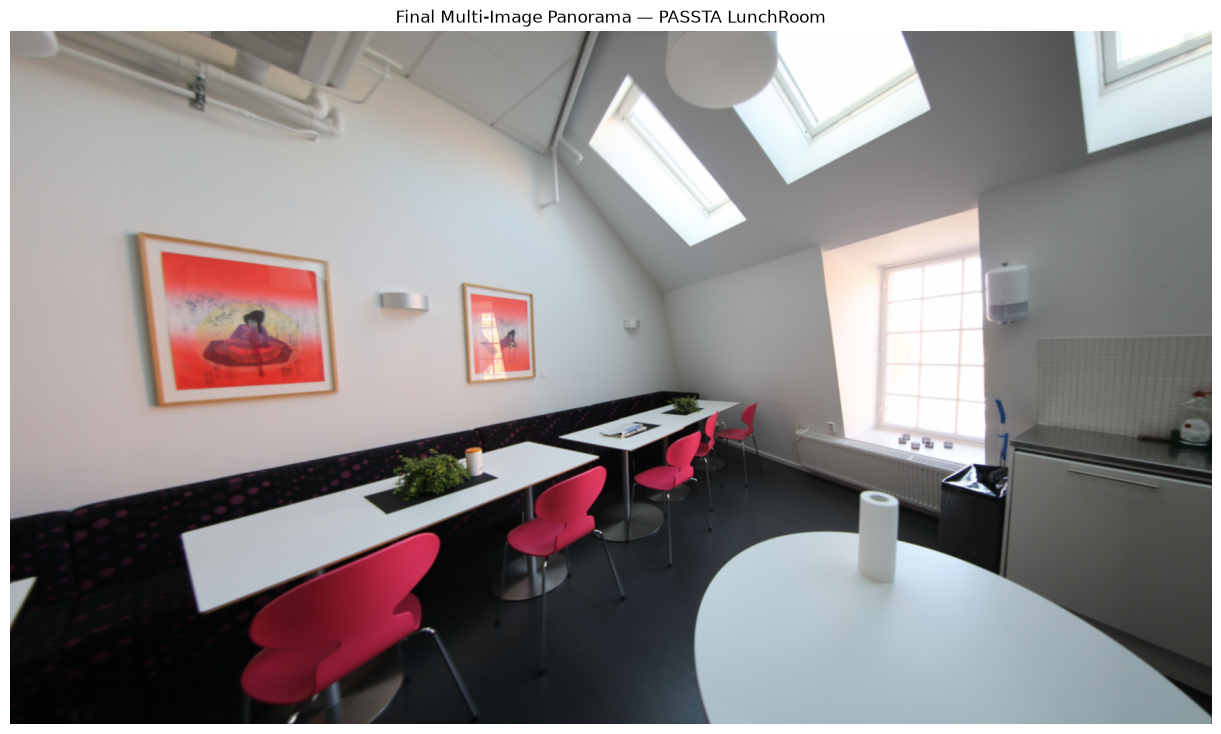

Final panorama dimensions: 1734 x 1000
Final file: D:\Task3_CV\panorama-stitching-computer-vision\outputs\final_panorama.png


In [19]:
plt.figure(figsize=(20, 9))
plt.imshow(cv2.cvtColor(panorama_final, cv2.COLOR_BGR2RGB))
plt.title("Final Multi-Image Panorama — PASSTA LunchRoom")
plt.axis("off")
plt.show()

print("Final panorama dimensions:", panorama_final.shape[1], "x", panorama_final.shape[0])
print("Final file:", final_path)

## 17. Pairwise Matching and RANSAC Summary

The following summary helps us inspect whether every adjacent image pair was aligned using a reasonable number of geometrically consistent matches.

In [20]:
print(
    f"{'Reference':<14} {'Source':<14} "
    f"{'Good':>7} {'Inliers':>9} {'Outliers':>9} {'Inlier ratio':>14}"
)
print("-" * 75)

for stats in pairwise_statistics:
    print(
        f"{stats['reference']:<14} "
        f"{stats['source']:<14} "
        f"{stats['good_matches']:>7} "
        f"{stats['inliers']:>9} "
        f"{stats['outliers']:>9} "
        f"{stats['inlier_ratio']:>13.3f}"
    )

mean_inlier_ratio = float(np.mean([
    stats["inlier_ratio"] for stats in pairwise_statistics
]))

print("\nMean pairwise inlier ratio:", round(mean_inlier_ratio, 3))
print("Number of stitched images:", len(images))
print("Reference image:", selected_paths[reference_index].name)

Reference      Source            Good   Inliers  Outliers   Inlier ratio
---------------------------------------------------------------------------
img01.jpg      img02.jpg          105       105         0         1.000
img02.jpg      img03.jpg          100       100         0         1.000
img03.jpg      img04.jpg          108       105         3         0.972
img04.jpg      img05.jpg          104       102         2         0.981
img05.jpg      img06.jpg           93        90         3         0.968
img06.jpg      img07.jpg           88        88         0         1.000
img07.jpg      img08.jpg           75        68         7         0.907
img08.jpg      img09.jpg           56        56         0         1.000
img09.jpg      img10.jpg           90        90         0         1.000
img10.jpg      img11.jpg           83        82         1         0.988
img11.jpg      img12.jpg           65        63         2         0.969

Mean pairwise inlier ratio: 0.98
Number of stitched images

## 18. Save a Reproducibility Summary

Save the selected filenames, processing settings, pairwise match statistics, and final panorama dimensions. This makes it easier to document the experiment and reproduce it later.

In [21]:
summary = {
    "dataset": "PASSTA LunchRoom",
    "selected_images": [path.name for path in selected_paths],
    "number_of_images": len(images),
    "reference_image": selected_paths[reference_index].name,
    "max_image_dimension": MAX_IMAGE_DIMENSION,
    "undistortion_requested": APPLY_UNDISTORTION,
    "undistortion_applied_to_all": all(
        item["undistortion_applied"] for item in image_metadata
    ),
    "harris": {
        "max_corners": MAX_CORNERS,
        "quality_level": HARRIS_QUALITY_LEVEL,
        "min_distance": HARRIS_MIN_DISTANCE,
        "k": HARRIS_K,
        "sift_keypoint_size": SIFT_KEYPOINT_SIZE
    },
    "matching": {
        "matcher": "BFMatcher",
        "norm": "NORM_L2",
        "knn_k": 2,
        "lowe_ratio": LOWE_RATIO
    },
    "ransac_reprojection_threshold": RANSAC_REPROJECTION_THRESHOLD,
    "canvas": {
        "width": canvas_width,
        "height": canvas_height
    },
    "final_panorama": {
        "width": int(panorama_final.shape[1]),
        "height": int(panorama_final.shape[0]),
        "file": str(final_path.relative_to(PROJECT_ROOT))
    },
    "pairwise_statistics": pairwise_statistics
}

summary_path = OUTPUT_DIR / "stitching_summary.json"
summary_path.write_text(
    json.dumps(summary, indent=4),
    encoding="utf-8"
)

print("Experiment summary saved to:", summary_path)

Experiment summary saved to: D:\Task3_CV\panorama-stitching-computer-vision\outputs\stitching_summary.json


## 19. Optional Comparison with OpenCV's Built-in Stitcher

This section is **only for comparison**. It is not the implementation used to produce the main project result.

The main pipeline above explicitly implements Harris, SIFT descriptors, matching, RANSAC, homography, warping, and blending. The built-in stitcher is a black-box reference that can be used to discuss differences.

OpenCV Stitcher status: 0 (0 means success)


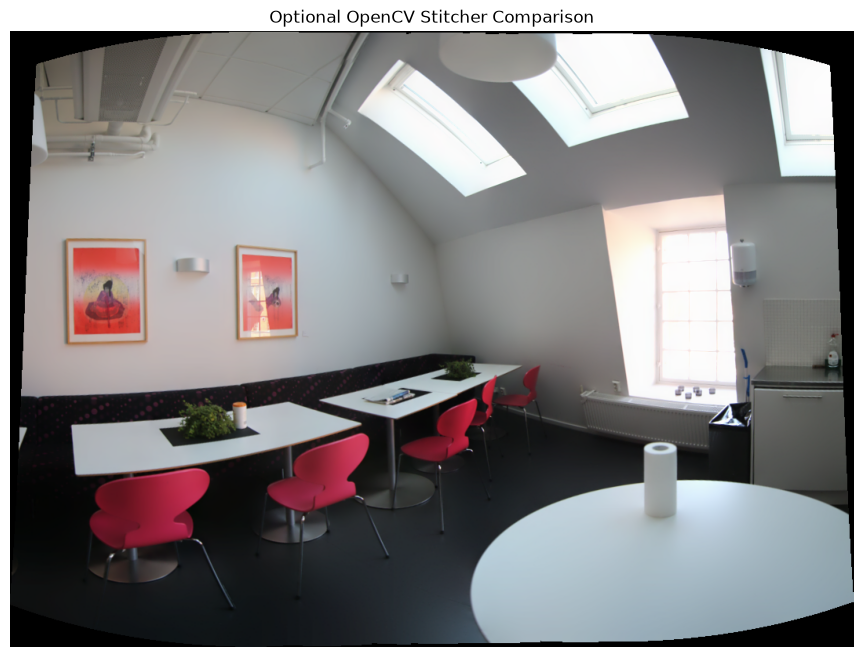

In [22]:
#Optional experiment — uncomment only if you want to compare results.

stitcher = cv2.Stitcher_create(cv2.Stitcher_PANORAMA)
status, automatic_panorama = stitcher.stitch(images)

print("OpenCV Stitcher status:", status, "(0 means success)")

if status == cv2.Stitcher_OK:
    automatic_path = OUTPUT_DIR / "opencv_stitcher_comparison.png"
    cv2.imwrite(str(automatic_path), automatic_panorama)

    plt.figure(figsize=(18, 8))
    plt.imshow(cv2.cvtColor(automatic_panorama, cv2.COLOR_BGR2RGB))
    plt.title("Optional OpenCV Stitcher Comparison")
    plt.axis("off")
    plt.show()
else:
    print("Built-in Stitcher did not produce a panorama for this image set.")

In [23]:

# Save the final feather-blended panorama as JPG
final_jpg_path = OUTPUT_DIR / "final_panorama.jpg"

success = cv2.imwrite(
    str(final_jpg_path),
    panorama_final,
    [cv2.IMWRITE_JPEG_QUALITY, 95]
)

if not success:
    raise RuntimeError("Failed to save final panorama JPG.")

print("Final JPG saved:", final_jpg_path)
print("Final dimensions:", panorama_final.shape[1], "x", panorama_final.shape[0])


Final JPG saved: D:\Task3_CV\panorama-stitching-computer-vision\outputs\final_panorama.jpg
Final dimensions: 1734 x 1000


## 20. Conclusion

The panorama stitching pipeline was successfully implemented using 12 consecutive images from the PASSTA LunchRoom dataset.

The implementation included Harris Corner Detection, SIFT Descriptors, BFMatcher, Lowe's Ratio Test, RANSAC-based Homography Estimation, Multi-Image Alignment, Image Warping, Feather Blending, and Cropping.

The 11 adjacent image pairs achieved an average inlier ratio of approximately 98%. The final panorama was generated with dimensions of 1734 × 1000 pixels.

### Limitations

- Camera undistortion was skipped because the image dimensions did not match the calibration resolution.
- Minor alignment errors may occur due to accumulated homography transformations.
- Exposure differences and parallax may affect blending quality.

## References

1. Meneghetti, G., Danelljan, M., Felsberg, M., & Nordberg, K. (2015). *Image alignment for panorama stitching in sparsely structured environments*. SCIA 2015. PASSTA dataset documentation and the associated paper should be cited in the final report.
2. Computer Vision — Lab 6: *Panorama Stitching Using Harris Corners and SIFT Descriptors* (course material).
3. OpenCV documentation: Feature Detection, Feature Matching, `findHomography`, `warpPerspective`, and image blending functions.